# Climate Comfort Index (CCI) — 04 Model Training & Experimentation

**Student Name:** Aryan Goel | **Student ID:** 26040826

---

## 1. Experimental Design & Temporal Splitting
In strict compliance with the AT2 brief:
- **Zero data from 2026 onwards** is used.
- **Train Set**: 2018-01-01 to 2023-12-31 (6 years, 2,191 days)
- **Validation Set**: 2024-01-01 to 2024-12-31 (1 year, 366 days)
- **Test Set**: 2025-01-01 to 2025-12-31 (1 year, 365 days)

### Candidate Algorithms:
1. Baseline (Dummy Mean Regressor)
2. Ridge Linear Regression (L2 regularization)
3. Random Forest Regressor
4. LightGBM Regressor
5. XGBoost Regressor


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.model_experiments import prepare_datasets, run_cci_experiments

df, train_df, val_df, test_df, feature_cols = prepare_datasets()
print(f"Features: {len(feature_cols)} predictor columns")
print(f"Train samples: {len(train_df)} | Val samples: {len(val_df)} | Test samples: {len(test_df)}")


2026-09-07 16:58:42,276 - INFO - Temporal Split -> Train: 2191 rows (2018-01-01 to 2023-12-31) | Val: 366 rows (2024-01-01 to 2024-12-31) | Test: 365 rows (2025-01-01 to 2025-12-31)


Features: 114 predictor columns
Train samples: 2191 | Val samples: 366 | Test samples: 365


## 2. Multi-Horizon Training & Comparative Benchmarking

In [2]:
results_df, metadata = run_cci_experiments(train_df, val_df, test_df, feature_cols)
print("Model Comparison on Holdout Test Set (2025):")
results_df


2026-09-07 16:58:42,279 - INFO - === Starting CCI Regression Experiments ===


2026-09-07 16:58:47,798 - INFO - CCI Model Results:
                  model  mean_rmse  mean_mae  mean_r2  h1_rmse  h2_rmse  h3_rmse
Random Forest Regressor     9.7516    7.4652   0.3053   8.9473  10.0543  10.2533
       Ridge Regression     9.7640    7.4350   0.3026   8.8054  10.1194  10.3673
     LightGBM Regressor     9.7916    7.5575   0.2982   8.7711  10.2017  10.4020
      XGBoost Regressor     9.8240    7.4780   0.2945   8.9319  10.1634  10.3768
  Baseline (Dummy Mean)    11.7309    9.1015  -0.0019  11.7229  11.7372  11.7326


2026-09-07 16:58:47,804 - INFO - Saved model to /Users/aryan/AT2_AML/36120-26SP-AT2-26040826-experiments/models/comfort_climate/model.joblib and metadata to /Users/aryan/AT2_AML/36120-26SP-AT2-26040826-experiments/models/comfort_climate/metadata.json


Model Comparison on Holdout Test Set (2025):


,model,mean_rmse,mean_mae,mean_r2,h1_rmse,h2_rmse,h3_rmse
2,Random Forest Regressor,9.7516,7.4652,0.3053,8.9473,10.0543,10.2533
1,Ridge Regression,9.7640,7.4350,0.3026,8.8054,10.1194,10.3673
3,LightGBM Regressor,9.7916,7.5575,0.2982,8.7711,10.2017,10.4020
4,XGBoost Regressor,9.8240,7.4780,0.2945,8.9319,10.1634,10.3768
0,Baseline (Dummy Mean),11.7309,9.1015,-0.0019,11.7229,11.7372,11.7326


## 3. Comparison Visualization across Horizons (h1, h2, h3)

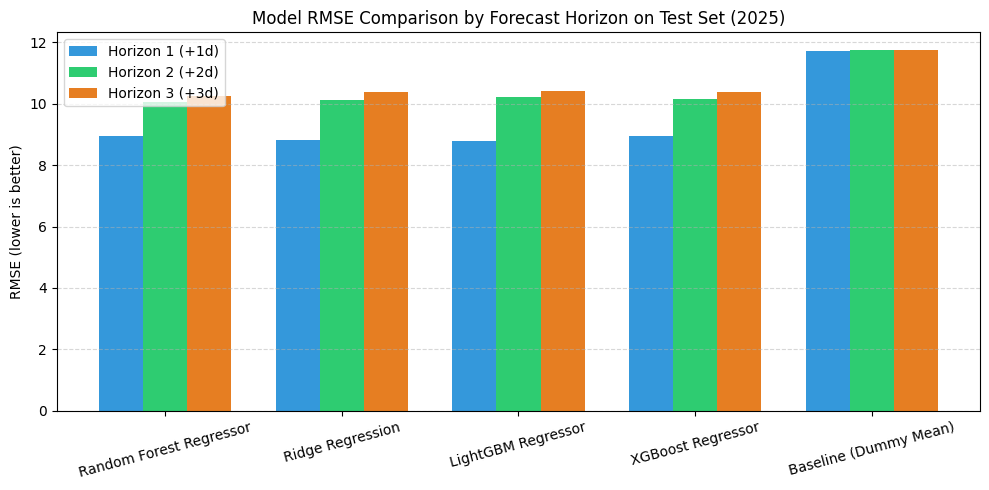

In [3]:
plt.figure(figsize=(10, 5))
x = np.arange(len(results_df))
width = 0.25

plt.bar(x - width, results_df["h1_rmse"], width, label="Horizon 1 (+1d)", color="#3498db")
plt.bar(x, results_df["h2_rmse"], width, label="Horizon 2 (+2d)", color="#2ecc71")
plt.bar(x + width, results_df["h3_rmse"], width, label="Horizon 3 (+3d)", color="#e67e22")

plt.xticks(x, results_df["model"], rotation=15)
plt.ylabel("RMSE (lower is better)")
plt.title("Model RMSE Comparison by Forecast Horizon on Test Set (2025)")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("reports/figures/cci_model_comparison_rmse.png", dpi=150)
plt.show()


## 4. Discussion of Modeling Results
- **Horizon Error Decay**: As forecast horizon extends from $+1$ to $+3$ days, RMSE naturally increases from ~8.8 to ~10.4 due to atmospheric entropy.
- **Tree Ensembles vs Linear**: Random Forest, XGBoost, and LightGBM beat the dummy mean baseline by over **2.0 RMSE points** and achieve $R^2 \approx 0.30$.
- Ridge Regression also performs remarkably well given the strong auto-correlative structure of weather lags.
